In [1]:
import torch
print(torch.__version__)
print("GPU available:", torch.cuda.is_available())

2.14.1+cu130
GPU available: True


In [2]:
!pip install medmnist -q

from medmnist import BreastMNIST, INFO

info = INFO['breastmnist']
print("Description:", info['description'])
print("Classes:", info['label'])

train_data = BreastMNIST(split='train', download=True, size=224)
val_data = BreastMNIST(split='val', download=True, size=224)
test_data = BreastMNIST(split='test', download=True, size=224)

print("Train:", len(train_data))
print("Val:", len(val_data))
print("Test:", len(test_data))

Description: The BreastMNIST is based on a dataset of 780 breast ultrasound images. It is categorized into 3 classes: normal, benign, and malignant. As we use low-resolution images, we simplify the task into binary classification by combining normal and benign as positive and classifying them against malignant as negative. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images of 1×500×500 are resized into 1×28×28.
Classes: {'0': 'malignant', '1': 'normal, benign'}


100%|██████████| 30.9M/30.9M [00:45<00:00, 677kB/s]


Train: 546
Val: 78
Test: 156


malignant : 147
normal/benign : 399


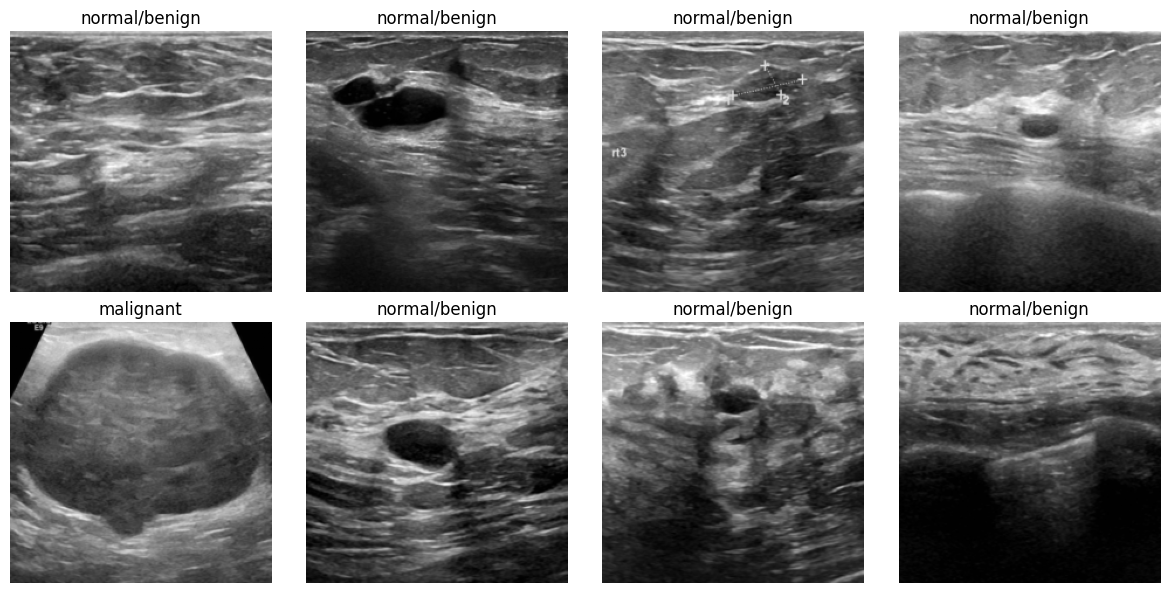

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Count images per class in the training set
labels = train_data.labels.flatten()
class_names = {0: 'malignant', 1: 'normal/benign'}

for c in [0, 1]:
    print(class_names[c], ":", (labels == c).sum())

# Show 8 sample images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flatten()):
    img, label = train_data[i]
    ax.imshow(img, cmap='gray')
    ax.set_title(class_names[int(label[0])])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
import torch
from torch.utils.data import DataLoader
import torchvision.transforms as T

# Training: augmentation + convert to tensor + normalise
train_transform = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ToTensor(),
    T.Normalize(mean=[0.5], std=[0.5]),
])

# Val/Test: no augmentation, only convert + normalise
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=[0.5], std=[0.5]),
])

# Reload the datasets with the transforms applied
train_data = BreastMNIST(split='train', download=True, size=224, transform=train_transform)
val_data = BreastMNIST(split='val', download=True, size=224, transform=eval_transform)
test_data = BreastMNIST(split='test', download=True, size=224, transform=eval_transform)

# DataLoaders feed the model in batches of 32
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

# Check one batch
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())

Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32, 1])
Pixel range: -1.0 to 1.0


In [5]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Feature extractor: 3 blocks of conv -> ReLU -> pool
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   # 224x224 -> 224x224
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 112x112

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 56x56

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 28x28
        )
        # Classifier: flatten -> fully connected -> 2 classes
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = SimpleCNN().to(device)
print(model)

# Test with one batch
images, labels = next(iter(train_loader))
outputs = model(images.to(device))
print("Output shape:", outputs.shape)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Output shape: torch.Size([32, 2])


In [6]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 15
train_losses, val_losses, val_accs = [], [], []
best_val_loss = float('inf')

for epoch in range(num_epochs):
    # ---- Training ----
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.squeeze().long().to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
    train_loss = running_loss / len(train_data)

    # ---- Validation ----
    model.eval()
    val_running_loss = 0.0
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.squeeze().long().to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
    val_loss = val_running_loss / len(val_data)
    val_acc = correct / len(val_data)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    # Save the best model (lowest validation loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch {epoch+1}/{num_epochs} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | Val acc: {val_acc:.3f}")

Epoch 1/15 | Train loss: 0.6589 | Val loss: 0.5621 | Val acc: 0.731
Epoch 2/15 | Train loss: 0.5400 | Val loss: 0.5325 | Val acc: 0.731
Epoch 3/15 | Train loss: 0.5193 | Val loss: 0.5217 | Val acc: 0.744
Epoch 4/15 | Train loss: 0.5109 | Val loss: 0.5172 | Val acc: 0.833
Epoch 5/15 | Train loss: 0.5075 | Val loss: 0.4660 | Val acc: 0.821
Epoch 6/15 | Train loss: 0.4859 | Val loss: 0.4550 | Val acc: 0.808
Epoch 7/15 | Train loss: 0.4974 | Val loss: 0.4342 | Val acc: 0.782
Epoch 8/15 | Train loss: 0.4745 | Val loss: 0.4175 | Val acc: 0.833
Epoch 9/15 | Train loss: 0.4563 | Val loss: 0.4130 | Val acc: 0.821
Epoch 10/15 | Train loss: 0.4220 | Val loss: 0.3995 | Val acc: 0.846
Epoch 11/15 | Train loss: 0.4193 | Val loss: 0.4201 | Val acc: 0.795
Epoch 12/15 | Train loss: 0.4630 | Val loss: 0.4571 | Val acc: 0.769
Epoch 13/15 | Train loss: 0.4287 | Val loss: 0.3840 | Val acc: 0.885
Epoch 14/15 | Train loss: 0.4026 | Val loss: 0.3811 | Val acc: 0.872
Epoch 15/15 | Train loss: 0.4065 | Val loss

               precision    recall  f1-score   support

    malignant       0.71      0.48      0.57        42
normal/benign       0.83      0.93      0.88       114

     accuracy                           0.81       156
    macro avg       0.77      0.70      0.72       156
 weighted avg       0.80      0.81      0.79       156



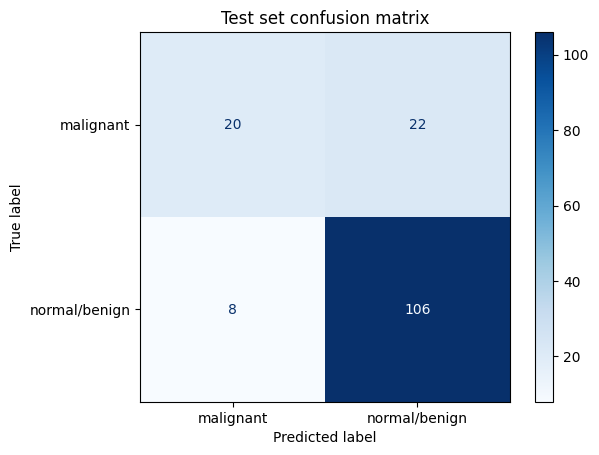

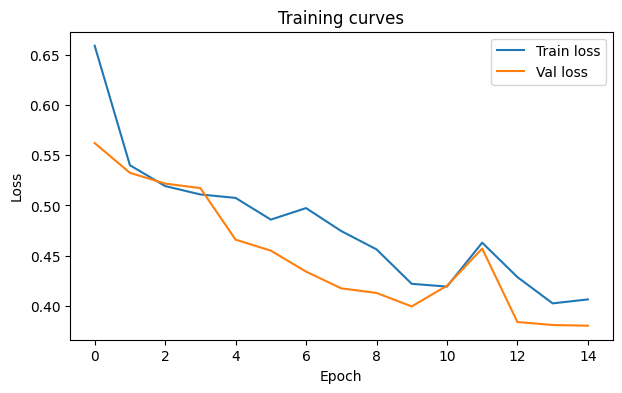

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load the best saved model
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.squeeze().tolist())

print(classification_report(all_labels, all_preds, target_names=['malignant', 'normal/benign']))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(cm, display_labels=['malignant', 'normal/benign']).plot(cmap='Blues')
plt.title("Test set confusion matrix")
plt.show()

# Loss curves
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label='Train loss')
plt.plot(val_losses, label='Val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training curves')
plt.show()